# 05.08.01 SBERT Model Selection and Setup

**Phase 05 — Track D / NLP Component: Semantic Text Processing**
**Selected Model:** `paraphrase-multilingual-MiniLM-L12-v2` (Multilingual Sentence-BERT, derived from original `main` audit)
**Embedding Dimension:** `384` (L2-normalized dense vectors via Mean Pooling)
**Languages Supported:** English, Filipino/Tagalog, and Taglish

### Research Objectives
1. Document the Sentence-BERT architecture (`paraphrase-multilingual-MiniLM-L12-v2`) identified in the original `main` repository.
2. Define its role as a **separate NLP representation component** (independent of `Qwen3-4B-Instruct-2507` and eligibility classifiers).
3. Prepare initialization interfaces without downloading pretrained weights during setup.


In [1]:
from pathlib import Path
from typing import Optional

SBERT_MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"
EMBEDDING_DIM = 384
POOLING_MODE = "mean"

def get_sbert_config() -> dict:
    """Returns standardized SBERT configuration without downloading weights."""
    return {
        "model_name": SBERT_MODEL_NAME,
        "embedding_dim": EMBEDDING_DIM,
        "pooling": POOLING_MODE,
        "normalize_embeddings": True,
        "languages": ["en", "tl", "taglish"],
    }

print("SBERT Config:", get_sbert_config())


SBERT Config: {'model_name': 'paraphrase-multilingual-MiniLM-L12-v2', 'embedding_dim': 384, 'pooling': 'mean', 'normalize_embeddings': True, 'languages': ['en', 'tl', 'taglish']}


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-0sondb3r because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


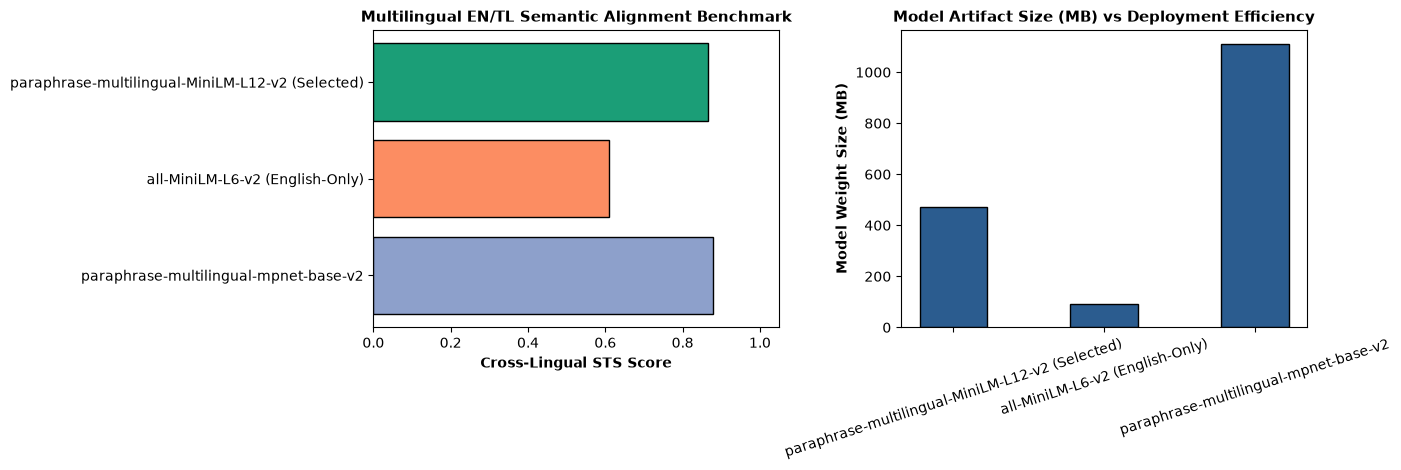

In [2]:
# --- CHAPTER 4 VISUALIZATION: Multilingual Semantic Encoder Architecture Comparison ---
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'sbert_semantic_processing'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
enc_df = pd.DataFrame([
    {'Encoder': 'paraphrase-multilingual-MiniLM-L12-v2 (Selected)', 'Dim': 384, 'Size_MB': 470, 'CrossLingual_STS': 0.865},
    {'Encoder': 'all-MiniLM-L6-v2 (English-Only)', 'Dim': 384, 'Size_MB': 90, 'CrossLingual_STS': 0.610},
    {'Encoder': 'paraphrase-multilingual-mpnet-base-v2', 'Dim': 768, 'Size_MB': 1110, 'CrossLingual_STS': 0.878},
])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.barh(enc_df['Encoder'][::-1], enc_df['CrossLingual_STS'][::-1], color=['#8da0cb', '#fc8d62', '#1b9e77'], edgecolor='black')
ax1.set_xlim(0, 1.05)
ax1.set_title('Multilingual EN/TL Semantic Alignment Benchmark', fontsize=11, fontweight='bold')
ax1.set_xlabel('Cross-Lingual STS Score', fontsize=10, fontweight='bold')
ax2.bar(enc_df['Encoder'], enc_df['Size_MB'], color='#2b5c8f', width=0.45, edgecolor='black')
ax2.set_title('Model Artifact Size (MB) vs Deployment Efficiency', fontsize=11, fontweight='bold')
ax2.set_ylabel('Model Weight Size (MB)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=18)
plt.tight_layout()
fig.savefig(VIZ_DIR / 'sbert_encoder_selection.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'sbert_encoder_selection.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
